# How much is manipulated? Levenshtein distance per condition and block

For every story, the three conditions are built from the same IPA and compared with the **native** IPA:

| condition | t / k | vowels |
|---|---|---|
| **native** | – | – |
| **consistent** | block *b*: every t → `T_ALTS[b]`, every k → `K_ALTS[b]` | block *b*: **every** instance of one vowel (`CONSISTENT_VOWELS[b]`) → its replacement |
| **inconsistent** | every t / k → one of the three alternatives, 33 % each (one draw per word) | `word_quota` over the whole story; by default each vowel gets **the same number of words and phonemes that the consistent condition changed**; or type your own numbers in `INCONSISTENT_VOWEL_QUOTA` |

**Distance.** Levenshtein distance between the native and the manipulated IPA, on **phoneme units**: a phoneme together with its diacritics (`tʲ`, `tː`, `ẽ`) is one unit, so t → tʲ is one substitution; stress marks are ignored. It is computed word by word (the manipulations never add or remove words) and summed per sentence, block and story.
- `lev`: every substitution / insertion / deletion costs 1
- `lev_w`: **weighted**, every substitution costs the weight YOU give it in `SUB_WEIGHTS` (prefilled with the number of features that change); pairs you did not list fall back to the feature table (or a fixed number)

**Per-word normalization (main measure).** For every word: `d = distance / number of phonemes in the native word` (0 for an unchanged word). Then the mean over the words of a sentence (unchanged words included), the mean of the sentence means in a block, and the mean of the three block means for the story:
- `pw`   = that mean for `lev`, in %   (e.g. one change in a 5-phoneme word = 20 %)
- `pw_w` = the same for `lev_w`

The table also keeps the pooled measures `lev_100` / `lev_w_100` (total distance / total phonemes × 100) for comparison.

Nothing is synthesized.

In [1]:
from functions import text_to_ipa_chunks, one_sentence_chunks, VOWELS, BOUNDARY, VOCAB
from word_quota import manipulate_with_quota, normalize_ipa, _word_spans
import re, csv, os, itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from collections import Counter, defaultdict
from IPython.display import display, HTML

c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  warnings.warn(
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## Settings
**Stories.** One file per story, next to this notebook (`story1.txt`, `story2.txt`, `story3.txt`). Mark the block boundaries with a line containing only `###`.
If a story has no `###`, it is cut automatically into `N_BLOCKS` blocks of similar word count at sentence boundaries (useful for a quick test, but use your own blocks for the real thing).

In [2]:
from pathlib import Path
story1 = Path("story1.txt").read_text(encoding="utf-8")
story2 = Path("story2.txt").read_text(encoding="utf-8")
story3 = Path("story3.txt").read_text(encoding="utf-8")
STORIES = {
    "story1": story1,
    "story2": story2,
    "story3": story3,
}
BLOCK_SEP = "###"
N_BLOCKS  = 3
NORMALIZE = {"ɪ": "i"}

# ---- consonants ----
T_ALTS = ["tʲ", "θ", "ɖ"]           # consistent: block 1, 2, 3   | inconsistent: 33 % each
K_ALTS = ["x", "ɡ", "kʲ"]           # ɡ = U+0261 (the g in Kokoro's vocab), not the ASCII g
INCONSISTENT_SAME_IN_WORD = True     # inconsistent: every t (k) of one word gets the same alternative

# ---- vowels ----
VOWEL_TARGETS = {"e": dict(new="ø"),     # replacement of each vowel (both conditions)
                 "i": dict(new="y"),
                 "o": dict(new="ə")}
CONSISTENT_VOWELS = ["i","e","o" ]  # consistent: block 1 changes EVERY e, block 2 every i, block 3 every o
# inconsistent: how many words / phonemes of each vowel to change over the whole story.
#   None                      -> every story matches its OWN consistent condition
#   a story name, per story   -> match the consistent condition of THAT story:
#                                {"story2": "story1"}   story 2 inconsistent = story 1 consistent counts
#   numbers                   -> {"e": dict(words=290, phonemes=320), ...}  (for every story, or per story)
#   mixed, per vowel          -> {"story2": {"e": "story1", "i": dict(words=223, phonemes=246)}}
#   a story / vowel that is not listed keeps its own consistent counts
INCONSISTENT_VOWEL_QUOTA = {
    "story1": "story1",       # story 1 inconsistent: as many e/i/o words + phonemes as story 1 consistent
    "story2": "story2",       # story 2 inconsistent: as many e/i/o words + phonemes as story 1 consistent
    "story3": "story3",     # same for story 3, if you want it
}
OCCURRENCES = "all"                  # inconsistent: "all" (every e of a chosen word) or "partial"

SEED    = 1                          # the seed used for the main tables
N_SEEDS = 20                         # seeds for the variability check

# every alternative must be a Kokoro token, otherwise it would be dropped from the speech
_bad = [a for a in T_ALTS + K_ALTS + [v["new"] for v in VOWEL_TARGETS.values()] if any(c not in VOCAB for c in a)]
assert not _bad, f"not in Kokoro's vocab: {_bad}  (for g use 'ɡ' U+0261)"

### Feature table (fallback for pairs not in `SUB_WEIGHTS`, and for `WEIGHTING = "features"`)
Each base phoneme gets one value per feature; the cost of a substitution is the number of features with different values, plus one per diacritic feature (ʲ ʰ ː ̃) that differs. A consonant ↔ vowel substitution costs 3 + diacritics. Unknown symbols cost 1.

In [3]:
CONS = {   # voice, place, manner
 'p':('-','bilabial','stop'), 'b':('+','bilabial','stop'), 'm':('+','bilabial','nasal'),
 'ɸ':('-','bilabial','fricative'), 'β':('+','bilabial','fricative'),
 'f':('-','labiodental','fricative'), 'v':('+','labiodental','fricative'), 'ʋ':('+','labiodental','approximant'),
 'θ':('-','dental','fricative'), 'ð':('+','dental','fricative'),
 't':('-','alveolar','stop'), 'd':('+','alveolar','stop'), 'n':('+','alveolar','nasal'),
 's':('-','alveolar','fricative'), 'z':('+','alveolar','fricative'), 'S':('-','alveolar','fricative'),
 'ʦ':('-','alveolar','affricate'), 'ʣ':('+','alveolar','affricate'),
 'r':('+','alveolar','trill'), 'ɾ':('+','alveolar','tap'), 'ɹ':('+','alveolar','approximant'), 'l':('+','alveolar','lateral'),
 'ʃ':('-','postalveolar','fricative'), 'ʒ':('+','postalveolar','fricative'),
 'ʧ':('-','postalveolar','affricate'), 'ʤ':('+','postalveolar','affricate'),
 'ɕ':('-','alveolopalatal','fricative'), 'ʨ':('-','alveolopalatal','affricate'), 'ʥ':('+','alveolopalatal','affricate'),
 'ʈ':('-','retroflex','stop'), 'ɖ':('+','retroflex','stop'), 'ɳ':('+','retroflex','nasal'),
 'ʂ':('-','retroflex','fricative'), 'ɽ':('+','retroflex','tap'), 'ɻ':('+','retroflex','approximant'),
 'c':('-','palatal','stop'), 'ɟ':('+','palatal','stop'), 'ɲ':('+','palatal','nasal'), 'ç':('-','palatal','fricative'),
 'ʝ':('+','palatal','fricative'), 'j':('+','palatal','approximant'), 'ʎ':('+','palatal','lateral'),
 'k':('-','velar','stop'), 'ɡ':('+','velar','stop'), 'g':('+','velar','stop'), 'ŋ':('+','velar','nasal'),
 'x':('-','velar','fricative'), 'ɣ':('+','velar','fricative'), 'ɰ':('+','velar','approximant'),
 'w':('+','labiovelar','approximant'),
 'q':('-','uvular','stop'), 'ɴ':('+','uvular','nasal'), 'χ':('-','uvular','fricative'), 'ʁ':('+','uvular','fricative'),
 'h':('-','glottal','fricative'), 'ʔ':('-','glottal','stop'),
}
VOWS = {   # height, backness, rounding
 'i':('close','front','-'), 'y':('close','front','+'), 'ɨ':('close','central','-'), 'ɯ':('close','back','-'),
 'u':('close','back','+'), 'ɪ':('near-close','front','-'), 'ʊ':('near-close','back','+'),
 'e':('close-mid','front','-'), 'ø':('close-mid','front','+'), 'ɤ':('close-mid','back','-'), 'o':('close-mid','back','+'),
 'ə':('mid','central','-'),
 'ɛ':('open-mid','front','-'), 'œ':('open-mid','front','+'), 'ɜ':('open-mid','central','-'),
 'ʌ':('open-mid','back','-'), 'ɔ':('open-mid','back','+'),
 'æ':('near-open','front','-'), 'ɐ':('near-open','central','-'),
 'a':('open','front','-'), 'ɑ':('open','back','-'), 'ɒ':('open','back','+'),
}
DIACRITICS = {'ʲ': 'palatalized', 'ʰ': 'aspirated', 'ː': 'long', '̃': 'nasalized'}
INDEL_FEAT = 3          # cost of inserting / deleting a whole unit in lev_feat
# misaki writes some diphthongs as one capital letter: features of the first vowel + "diphthong"
DIPHTHONGS = {'A': 'e', 'I': 'a', 'W': 'a', 'O': 'o', 'Q': 'ə', 'Y': 'ɔ'}     # eɪ aɪ aʊ oʊ əʊ ɔɪ

### Your weights (for `lev_w`)
One weight per substitution, native → replacement. Prefilled with the number of features that change; put any numbers you like.
Diacritics shared by both sides are ignored when looking a pair up, so `tː → tʲː` uses the weight of `t → tʲ`.

In [ ]:
WEIGHTING = "manual"        # "manual": SUB_WEIGHTS below; "features": ignore SUB_WEIGHTS, count features
SUB_WEIGHTS = {
    ("t", "tʲ"): 0.5,         # palatalization
    ("t", "θ"):  2,         # place, manner
    ("t", "ɖ"):  1,         # voicing
    ("k", "x"):  2,         # manner
    ("k", "ɡ"):  1,         # voicing
    ("k", "kʲ"): 0.5,         # palatalization
    ("e", "ø"):  1,         # rounding
    ("i", "y"):  1,         # rounding
    ("o", "ə"):  1,         # height, backness, rounding
}
MISSING_WEIGHT = "features" # a pair not in SUB_WEIGHTS: "features" (feature count) or a number, e.g. 1
INDEL_WEIGHT = 3            # insertion / deletion of a whole phoneme (does not happen with these rules)

## Phoneme units and Levenshtein distance

In [5]:
STRESS = {"ˈ", "ˌ"}

def units(word):
    '''A word -> list of (base, frozenset(diacritic features)); stress marks dropped.'''
    out = []
    for c in word:
        if c in STRESS:
            continue
        if c in DIACRITICS and out:
            b, d = out[-1]; out[-1] = (b, d | {DIACRITICS[c]})
        elif c in DIACRITICS or c in BOUNDARY:
            continue
        else:
            out.append((c, frozenset({"long"}) if c == "S" else frozenset()))
    return out

_unknown = set()
def feat_cost(a, b):
    '''Number of features that differ between two units.'''
    if a == b:
        return 0
    (ba, da), (bb, db) = a, b
    dia = len(da ^ db) + ((ba in DIPHTHONGS) != (bb in DIPHTHONGS))
    ba_, bb_ = DIPHTHONGS.get(ba, ba), DIPHTHONGS.get(bb, bb)
    if ba != bb and ba_ == bb_:                      # e.g. A (eɪ) vs I... same first vowel, different glide
        return max(dia, 1)
    ba, bb = ba_, bb_
    fa = CONS.get(ba) or VOWS.get(ba); fb = CONS.get(bb) or VOWS.get(bb)
    if fa is None or fb is None:
        _unknown.update(x for x, f in ((ba, fa), (bb, fb)) if f is None)
        return (ba != bb) + dia
    if (ba in CONS) != (bb in CONS):
        return 3 + dia
    return sum(x != y for x, y in zip(fa, fb)) + dia

def lev(a, b, cost=None, indel=1):
    '''Levenshtein distance between two unit lists + the list of edit operations (native, manipulated).'''
    cost = cost or (lambda x, y: 0 if x == y else 1)
    n, m = len(a), len(b)
    D = np.zeros((n + 1, m + 1)); D[:, 0] = np.arange(n + 1) * indel; D[0, :] = np.arange(m + 1) * indel
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i-1, j] + indel, D[i, j-1] + indel, D[i-1, j-1] + cost(a[i-1], b[j-1]))
    ops, i, j = [], n, m                                     # backtrace
    while i or j:
        if i and j and D[i, j] == D[i-1, j-1] + cost(a[i-1], b[j-1]):
            if a[i-1] != b[j-1]: ops.append((a[i-1], b[j-1]))
            i, j = i - 1, j - 1
        elif i and D[i, j] == D[i-1, j] + indel:
            ops.append((a[i-1], None)); i -= 1
        else:
            ops.append((None, b[j-1])); j -= 1
    return D[n, m], ops[::-1]

def show(u):
    if u is None: return "∅"
    b, d = u
    return b + "".join(k for k, v in DIACRITICS.items() if v in d)

def _key(a, b):
    # (native, replacement) as strings, diacritics shared by both sides removed
    (ba, da), (bb, db) = a, b
    common = da & db
    return show((ba, da - common)), show((bb, db - common))

_missing = Counter()
def weight(a, b):
    # your weight for substituting unit a by unit b
    if a == b:
        return 0
    if WEIGHTING == "manual":
        key = _key(a, b)
        if key in SUB_WEIGHTS:
            return SUB_WEIGHTS[key]
        if MISSING_WEIGHT != "features":
            return MISSING_WEIGHT
    return feat_cost(a, b)

def weight_source(a, b):
    if WEIGHTING != "manual":
        return "features"
    if _key(a, b) in SUB_WEIGHTS:
        return "yours"
    return "fixed" if MISSING_WEIGHT != "features" else "features"

# quick check
assert lev(units("ˈtetto"), units("ˈtʲetʲto"))[0] == 2
assert lev(units("kasa"), units("xasa"), feat_cost)[0] == 1        # k -> x: manner only
assert feat_cost(units("t")[0], units("θ")[0]) == 2                  # place + manner
print("ok")

ok


## Building the three conditions
`build_story(name, text, seed)` → for every condition a list of blocks, each block a list of (native IPA, manipulated IPA) sentences.

In [6]:
_auto_warned = set()

def split_blocks(text):
    '''Blocks from ### lines, or N_BLOCKS blocks of similar word count at sentence boundaries.'''
    parts = [p.strip() for p in re.split(rf"^\s*{re.escape(BLOCK_SEP)}\s*$", text, flags=re.M) if p.strip()]
    if len(parts) > 1:
        return parts
    sents = one_sentence_chunks(text)
    nw = np.cumsum([len(s.split()) for s in sents])
    cuts = [int(np.argmin(np.abs(nw - nw[-1] * b / N_BLOCKS))) + 1 for b in range(1, N_BLOCKS)]
    bounds = [0] + cuts + [len(sents)]
    if text not in _auto_warned:
        print(f"   (no '{BLOCK_SEP}' found: cut automatically into {N_BLOCKS} blocks)"); _auto_warned.add(text)
    return [" ".join(sents[a:b]) for a, b in zip(bounds, bounds[1:])]

def consistent_counts(nat):
    '''Words and phonemes of each vowel that the consistent condition changes (= all of them in its block).'''
    cnt = {v: dict(words=0, phonemes=0) for v in VOWEL_TARGETS}
    for b, chunks in enumerate(nat):
        v = CONSISTENT_VOWELS[b % len(CONSISTENT_VOWELS)]
        for s in chunks:
            for a, c in _word_spans(s):
                n = s[a:c].count(v)
                cnt[v]["words"] += n > 0; cnt[v]["phonemes"] += n
    return cnt

_CONS_COUNTS = {}
def consistent_counts_of(story_name):
    # vowel words / phonemes changed by the consistent condition of ANOTHER story (cached)
    if story_name not in _CONS_COUNTS:
        nat = [normalize_ipa(text_to_ipa_chunks(b), NORMALIZE, verbose=False) for b in split_blocks(STORIES[story_name])]
        _CONS_COUNTS[story_name] = consistent_counts(nat)
    return _CONS_COUNTS[story_name]

def inconsistent_vowel_rule(quota):
    return {"kind": "word_quota", "occurrences": OCCURRENCES, "batch": 10, "order": "rotate",
            "targets": [{"old": v, "new": VOWEL_TARGETS[v]["new"], "words": quota[v]["words"],
                         "phonemes": quota[v]["phonemes"]} for v in VOWEL_TARGETS if quota[v]["words"] > 0]}

def build_story(text, seed, verbose=False, name=None):
    blocks = split_blocks(text)
    nat = [normalize_ipa(text_to_ipa_chunks(b), NORMALIZE, verbose=False) for b in blocks]
    out = {"native": [list(zip(c, c)) for c in nat]}
    # consistent: ONE fixed substitution per block (every t, every k, every instance of the block's vowel)
    cons = []
    for b, chunks in enumerate(nat):
        v = CONSISTENT_VOWELS[b % len(CONSISTENT_VOWELS)]
        mp = {"t": T_ALTS[b % len(T_ALTS)], "k": K_ALTS[b % len(K_ALTS)], v: VOWEL_TARGETS[v]["new"]}
        m, st = manipulate_with_quota(chunks, [{"kind": "substitute", "map": mp}], return_stats=True, verbose=False)
        if verbose:
            n = {g["old"]: g["total"] for g in st[0]["groups"]}
            print(f"consistent, block {b + 1}: " + ", ".join(f"{o}→{mp[o]} ×{n.get(o, 0)}" for o in mp))
        cons.append(list(zip(chunks, m)))
    out["consistent"] = cons
    # inconsistent: t / k 33 % each, vowel quotas over the whole story
    quota = consistent_counts(nat)                     # default: same as this story's consistent condition
    src = {v: "= consistent" for v in quota}
    given = INCONSISTENT_VOWEL_QUOTA or {}
    if isinstance(given, dict) and any(k in STORIES for k in given):   # one entry per story
        given = given.get(name, {})
    if isinstance(given, str):                         # "story1" -> every vowel from story1's consistent
        given = {v: given for v in VOWEL_TARGETS}
    for v, q in given.items():
        assert v in VOWEL_TARGETS, f"INCONSISTENT_VOWEL_QUOTA: {v!r} is not in VOWEL_TARGETS"
        if isinstance(q, str):                         # "story1" -> that story's consistent counts
            assert q in STORIES, f"INCONSISTENT_VOWEL_QUOTA: unknown story {q!r}"
            quota[v] = dict(consistent_counts_of(q)[v]); src[v] = f"= consistent {q}"
        else:
            quota[v] = dict(words=int(q["words"]), phonemes=q.get("phonemes")); src[v] = "yours"
    flat = [c for chunks in nat for c in chunks]
    rules = [{"kind": "substitute_prob", "same_in_word": INCONSISTENT_SAME_IN_WORD,
              "map": {"t": {a: 1 for a in T_ALTS}, "k": {a: 1 for a in K_ALTS}}},
             inconsistent_vowel_rule(quota)]
    if verbose:
        print("inconsistent, whole story, vowel quotas: "
              + ", ".join(f"{v} {q['words']} words / {q['phonemes']} phonemes ({src[v]})" for v, q in quota.items()))
    m = manipulate_with_quota(flat, rules, seed=seed, verbose=verbose)
    inc, k = [], 0
    for chunks in nat:
        inc.append(list(zip(chunks, m[k:k + len(chunks)]))); k += len(chunks)
    out["inconsistent"] = inc
    return out

## Measuring

In [7]:
CONDS = ["native", "consistent", "inconsistent"]

def category(op):
    a, b = op
    base = (a or b)[0]
    if base == "t": return "t"
    if base == "k": return "k"
    if base in VOWEL_TARGETS: return base
    return "other"

def measure(story, keep_words=False):
    '''-> rows (one per condition × block + "all"), the edit operations, and (optionally) one row per word.
    Per-word normalized: d = distance / phonemes of the native word; mean over the words of a sentence,
    mean of the sentence means in a block, mean of the block means for the story.'''
    rows, all_ops, words_out = [], [], []
    for cond in CONDS:
        for b, sents in enumerate(story[cond]):
            r = dict(condition=cond, block=b + 1, sentences=len(sents), words=0, phonemes=0,
                     words_changed=0, lev=0.0, lev_w=0.0)
            cats, s_pw, s_pw_w = Counter(), [], []
            for si, (nat_s, man_s) in enumerate(sents):
                wn = [nat_s[a:c] for a, c in _word_spans(nat_s)]
                wm = [man_s[a:c] for a, c in _word_spans(man_s)]
                pairs = list(zip(wn, wm)) if len(wn) == len(wm) else [(" ".join(wn), " ".join(wm))]
                d_words, dw_words = [], []
                for wi, (x, y) in enumerate(pairs):
                    ux, uy = units(x), units(y)
                    if not ux:
                        continue
                    d, ops = lev(ux, uy)
                    dw, _ = lev(ux, uy, weight, INDEL_WEIGHT)
                    d_words.append(d / len(ux)); dw_words.append(dw / len(ux))
                    r["lev"] += d; r["lev_w"] += dw; r["words_changed"] += d > 0
                    r["words"] += 1; r["phonemes"] += len(ux)
                    for op in ops:                    # ops = the substitutions on the final alignment only
                        cats[category(op)] += 1
                        if None not in op and WEIGHTING == "manual" and _key(*op) not in SUB_WEIGHTS:
                            _missing[_key(*op)] += 1
                        w_ = weight(*op) if None not in op else INDEL_WEIGHT
                        all_ops.append((cond, b + 1, show(op[0]), show(op[1]), w_,
                                        weight_source(*op) if None not in op else "indel"))
                    if keep_words:
                        words_out.append(dict(condition=cond, block=b + 1, sentence=si, word=wi, native=x, manipulated=y,
                                              phonemes=len(ux), lev=d, lev_w=dw, d=round(d / len(ux), 4),
                                              d_w=round(dw / len(ux), 4)))
                if d_words:
                    s_pw.append(np.mean(d_words)); s_pw_w.append(np.mean(dw_words))
            r["pw"] = 100 * float(np.mean(s_pw)); r["pw_w"] = 100 * float(np.mean(s_pw_w))
            r["lev_100"] = 100 * r["lev"] / r["phonemes"]; r["lev_w_100"] = 100 * r["lev_w"] / r["phonemes"]
            r.update({f"n_{c}": cats[c] for c in ["t", "k", *VOWEL_TARGETS, "other"]})
            rows.append(r)
    for cond in CONDS:                                        # whole story
        rs = [r for r in rows if r["condition"] == cond]
        tot = {k: sum(r[k] for r in rs) for k in rs[0]
               if k not in ("condition", "block", "pw", "pw_w", "lev_100", "lev_w_100")}
        tot.update(condition=cond, block="all",
                   pw=float(np.mean([r["pw"] for r in rs])), pw_w=float(np.mean([r["pw_w"] for r in rs])),
                   lev_100=100 * tot["lev"] / tot["phonemes"], lev_w_100=100 * tot["lev_w"] / tot["phonemes"])
        rows.append(tot)
    return (rows, all_ops, words_out) if keep_words else (rows, all_ops)

results, ops_all, words_all = {}, {}, {}
_missing.clear()
for name, txt in STORIES.items():
    print(f"── {name}")
    story = build_story(txt, SEED, verbose=True, name=name)
    results[name], ops_all[name], words_all[name] = measure(story, keep_words=True)
if _missing:
    print("⚠ substitutions not in SUB_WEIGHTS (weighted with", MISSING_WEIGHT, "):",
          ", ".join(f"{a}→{b} ×{n}" for (a, b), n in _missing.most_common()))
if _unknown:
    print("⚠ symbols not in the feature table (cost 1):", sorted(_unknown))

── story1
consistent, block 1: t→tʲ ×216, k→x ×116, i→y ×236
consistent, block 2: t→θ ×202, k→ɡ ×163, e→ø ×267
consistent, block 3: t→ɖ ×215, k→kʲ ×127, o→ə ×304
inconsistent, whole story, vowel quotas: e 248 words / 267 phonemes (= consistent story1), i 217 words / 236 phonemes (= consistent story1), o 248 words / 304 phonemes (= consistent story1)
word_quota: 1686 candidate words, 467 of them can take more than one target
   e → ø: 819 candidate words (912 phonemes) -> 248 of 248 words, 267 phonemes (target 267)
   i → y: 676 candidate words (740 phonemes) -> 217 of 217 words, 236 phonemes (target 236)
   o → ə: 728 candidate words (862 phonemes) -> 248 of 248 words, 304 phonemes (target 304)
── story2
consistent, block 1: t→tʲ ×206, k→x ×130, i→y ×271
consistent, block 2: t→θ ×226, k→ɡ ×109, e→ø ×339
consistent, block 3: t→ɖ ×234, k→kʲ ×127, o→ə ×300
inconsistent, whole story, vowel quotas: e 295 words / 339 phonemes (= consistent story2), i 241 words / 271 phonemes (= consistent st

## Results table

In [8]:
COLS = ["condition", "block", "sentences", "words", "phonemes", "words_changed", "pw", "pw_w",
        "lev", "lev_w", "lev_100", "lev_w_100", "n_t", "n_k", *[f"n_{v}" for v in VOWEL_TARGETS], "n_other"]

def table_html(rows):
    fmt = lambda v: f"{v:.1f}" if isinstance(v, float) else str(v)
    head = "".join(f"<th style='padding:3px 8px;text-align:right'>{c}</th>" for c in COLS)
    body = ""
    for r in rows:
        style = "font-weight:600;border-top:1px solid #ccc" if r["block"] == "all" else ""
        hl = lambda c: "background:#eef4fc;" if c in ("pw", "pw_w") else ""
        body += f"<tr style='{style}'>" + "".join(f"<td style='padding:2px 8px;text-align:right;{hl(c)}'>{fmt(r[c])}</td>" for c in COLS) + "</tr>"
    return f"<table style='border-collapse:collapse;font-size:12px;font-family:system-ui'><tr>{head}</tr>{body}</table>"

for name, rows in results.items():
    order = sorted(rows, key=lambda r: (CONDS.index(r["condition"]), str(r["block"])))
    display(HTML(f"<h4 style='margin:14px 0 4px'>{name}</h4>" + table_html(order)))
print("pw / pw_w = per-word normalized distance in % (word -> sentence mean -> block mean -> story = mean of blocks)")
print("lev_100 / lev_w_100 = pooled: total distance per 100 native phonemes;  n_* = number of edits per native phoneme")

condition,block,sentences,words,phonemes,words_changed,pw,pw_w,lev,lev_w,lev_100,lev_w_100,n_t,n_k,n_e,n_i,n_o,n_other
native,1,35,733,3275,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,2,35,735,3259,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,3,36,740,3309,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,all,106,2208,9843,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
consistent,1,35,733,3275,402,16.4,17.3,568.0,576.0,17.3,17.6,216,116,0,236,0,0
consistent,2,35,735,3259,435,20.7,25.1,632.0,834.0,19.4,25.6,202,163,267,0,0,0
consistent,3,36,740,3309,363,14.9,13.2,646.0,582.5,19.5,17.6,215,127,0,0,304,0
consistent,all,106,2208,9843,1200,17.3,18.5,1846.0,1992.5,18.8,20.2,633,406,267,236,304,0
inconsistent,1,35,733,3275,389,16.8,18.4,587.0,651.0,17.9,19.9,216,116,81,82,92,0
inconsistent,2,35,735,3259,421,18.2,19.8,620.0,685.0,19.0,21.0,202,163,84,72,99,0


condition,block,sentences,words,phonemes,words_changed,pw,pw_w,lev,lev_w,lev_100,lev_w_100,n_t,n_k,n_e,n_i,n_o,n_other
native,1,35,732,3256,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,2,34,734,3297,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,3,37,739,3336,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,all,106,2205,9889,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
consistent,1,35,732,3256,435,18.7,20.5,607.0,634.0,18.6,19.5,206,130,0,271,0,0
consistent,2,34,734,3297,443,22.1,27.1,674.0,900.0,20.4,27.3,226,109,339,0,0,0
consistent,3,37,739,3336,396,16.1,14.2,661.0,597.5,19.8,17.9,234,127,0,0,300,0
consistent,all,106,2205,9889,1274,19.0,20.6,1942.0,2131.5,19.6,21.6,666,366,339,271,300,0
inconsistent,1,35,732,3256,416,19.1,21.0,632.0,696.5,19.4,21.4,206,130,106,104,86,0
inconsistent,2,34,734,3297,419,18.6,20.4,620.0,682.5,18.8,20.7,226,109,116,70,99,0


condition,block,sentences,words,phonemes,words_changed,pw,pw_w,lev,lev_w,lev_100,lev_w_100,n_t,n_k,n_e,n_i,n_o,n_other
native,1,35,733,3516,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,2,36,733,3397,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,3,35,738,3468,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,all,106,2204,10381,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
consistent,1,35,733,3516,432,18.3,19.5,634.0,653.5,18.0,18.6,213,126,0,295,0,0
consistent,2,36,733,3397,434,20.5,25.0,659.0,877.0,19.4,25.8,218,120,321,0,0,0
consistent,3,35,738,3468,370,14.0,12.4,598.0,538.5,17.2,15.5,202,119,0,0,277,0
consistent,all,106,2204,10381,1236,17.6,19.0,1891.0,2069.0,18.2,19.9,633,365,321,295,277,0
inconsistent,1,35,733,3516,423,17.4,18.7,630.0,683.5,17.9,19.4,213,126,106,88,97,0
inconsistent,2,36,733,3397,411,17.8,19.2,631.0,685.5,18.6,20.2,218,120,108,97,88,0


pw / pw_w = per-word normalized distance in % (word -> sentence mean -> block mean -> story = mean of blocks)
lev_100 / lev_w_100 = pooled: total distance per 100 native phonemes;  n_* = number of edits per native phoneme


## Distance per block and condition

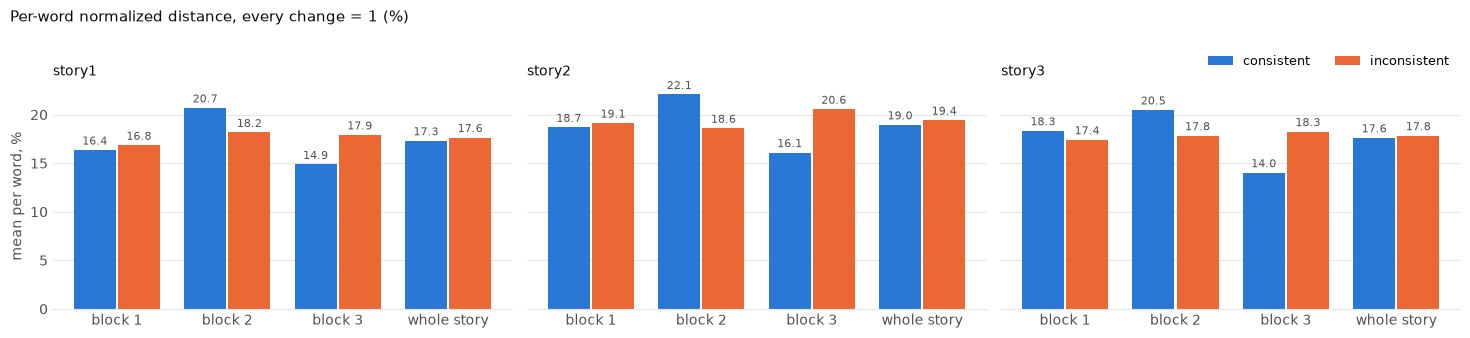

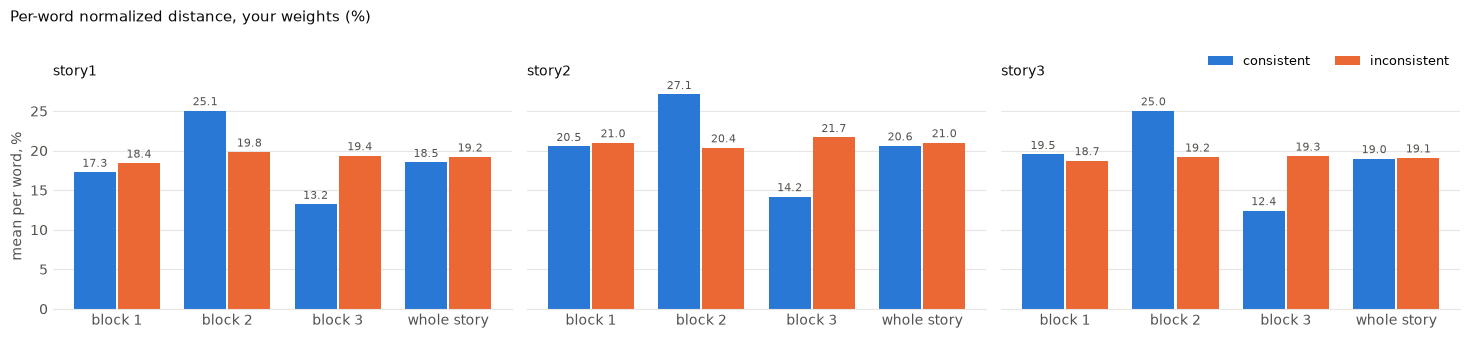

native is 0 everywhere (sanity check): True


In [9]:
C_COL = {"native": "#9ca3af", "consistent": "#2a78d6", "inconsistent": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e7e6e2"

def style(ax):
    ax.spines[["top", "right", "left"]].set_visible(False); ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0); ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)

for metric, title in (("pw", "Per-word normalized distance, every change = 1 (%)"),
                      ("pw_w", "Per-word normalized distance, your weights (%)")):
    names = list(results)
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names) + 1, 3.4), squeeze=False, sharey=True)
    for ax, name in zip(axes[0], names):
        rows = results[name]
        groups = sorted({r["block"] for r in rows if r["block"] != "all"}) + ["all"]
        x = np.arange(len(groups)); w = 0.38
        for k, cond in enumerate(["consistent", "inconsistent"]):
            v = [next(r[metric] for r in rows if r["condition"] == cond and r["block"] == g) for g in groups]
            bars = ax.bar(x + (k - 0.5) * (w + 0.02), v, w, color=C_COL[cond], label=cond)
            ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color=MUTED)
        ax.set_xticks(x, [f"block {g}" if g != "all" else "whole story" for g in groups], color=INK)
        ax.set_title(name, loc="left", fontsize=10, color=INK); style(ax)
    axes[0][0].set_ylabel("mean per word, %", color=MUTED)
    axes[0][-1].legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, color=INK)
    plt.tight_layout(); plt.show()
print("native is 0 everywhere (sanity check):",
      all(r["lev"] == 0 for rows in results.values() for r in rows if r["condition"] == "native"))

## What the distance is made of
Edits per block, split by the native phoneme that was changed.

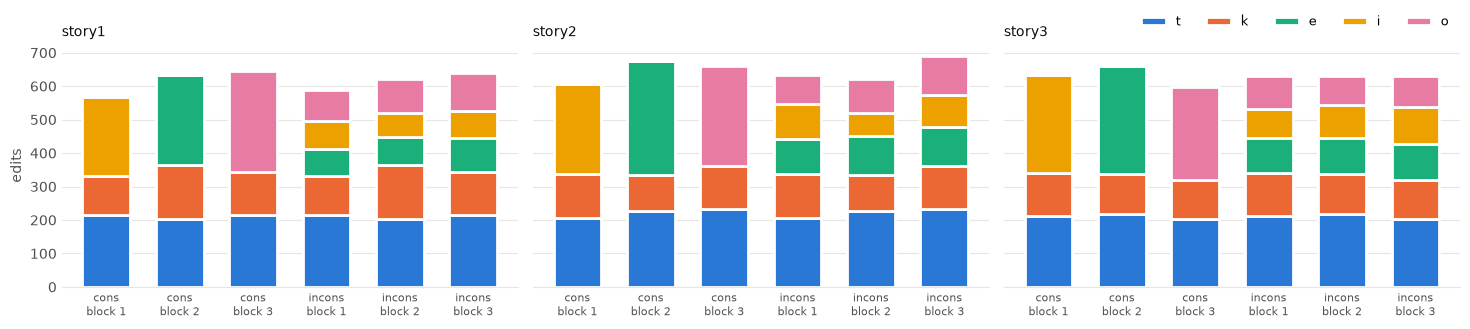

In [10]:
CATS = ["t", "k", *VOWEL_TARGETS, "other"]
CAT_COL = dict(zip(CATS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#9ca3af"]))
names = list(results)
fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names) + 1, 3.4), squeeze=False, sharey=True)
for ax, name in zip(axes[0], names):
    rows = [r for r in results[name] if r["block"] != "all" and r["condition"] != "native"]
    labels = [f"{'cons' if r['condition'] == 'consistent' else 'incons'}\nblock {r['block']}" for r in rows]
    bottom = np.zeros(len(rows))
    for c in CATS:
        v = np.array([r[f"n_{c}"] for r in rows])
        if v.sum() == 0: continue
        ax.bar(range(len(rows)), v, 0.65, bottom=bottom, color=CAT_COL[c], edgecolor="white", linewidth=2, label=c)
        bottom += v
    ax.set_xticks(range(len(rows)), labels, fontsize=8, color=INK)
    ax.set_title(name, loc="left", fontsize=10, color=INK); style(ax)
axes[0][0].set_ylabel("edits", color=MUTED)
axes[0][-1].legend(frameon=False, fontsize=9, ncol=len(CATS), loc="lower right", bbox_to_anchor=(1, 1.02))
plt.tight_layout(); plt.show()

## Which substitutions, and their weights
Every native → manipulated pair that occurred, with its count, the weight used and where it came from (`yours` = `SUB_WEIGHTS`, `features` = feature table).

In [11]:
for name, ops in ops_all.items():
    cnt = Counter((cond, a, b, w, src) for cond, blk, a, b, w, src in ops)
    print(f"── {name}")
    for cond in ["consistent", "inconsistent"]:
        items = sorted(((a, b, w, src, n) for (cd, a, b, w, src), n in cnt.items() if cd == cond), key=lambda x: (x[0], -x[4]))
        print(f"  {cond}:")
        for a, b, w, src, n in items:
            print(f"     {a:>3} → {b:<4} ×{n:<5} weight {w:<4} ({src})")

── story1
  consistent:
       e → ø    ×267   weight 1    (yours)
       i → y    ×236   weight 1    (yours)
       k → ɡ    ×153   weight 1    (yours)
       k → kʲ   ×115   weight 0.5  (yours)
       k → x    ×106   weight 2    (yours)
      kː → kʲː  ×12    weight 0.5  (yours)
      kː → xː   ×10    weight 2    (yours)
      kː → ɡː   ×10    weight 1    (yours)
       o → ə    ×304   weight 1    (yours)
       t → ɖ    ×192   weight 1    (yours)
       t → tʲ   ×175   weight 0.5  (yours)
       t → θ    ×175   weight 2    (yours)
      tː → tʲː  ×41    weight 0.5  (yours)
      tː → θː   ×27    weight 2    (yours)
      tː → ɖː   ×23    weight 1    (yours)
  inconsistent:
       e → ø    ×266   weight 1    (yours)
      eː → øː   ×1     weight 1    (yours)
       i → y    ×236   weight 1    (yours)
       k → kʲ   ×135   weight 0.5  (yours)
       k → x    ×131   weight 2    (yours)
       k → ɡ    ×108   weight 1    (yours)
      kː → ɡː   ×13    weight 1    (yours)
      kː → kʲː

## Variability over seeds
Only the inconsistent condition is random (which words get a vowel change, which t / k alternative is drawn); the consistent condition is the same for every seed. Mean ± SD over `N_SEEDS` seeds of the per-word normalized measures (%).

In [12]:
for name, txt in STORIES.items():
    acc = defaultdict(list)
    for sd in range(N_SEEDS):
        rows, _ = measure(build_story(txt, sd, name=name))
        for r in rows:
            if r["condition"] != "native":
                acc[(r["condition"], r["block"])].append((r["pw"], r["pw_w"]))
    print(f"── {name}   ({N_SEEDS} seeds)")
    print(f"   {'condition':<13}{'block':>6}{'pw %':>16}{'pw_w %':>16}")
    for (cond, blk), v in sorted(acc.items(), key=lambda kv: (kv[0][0], str(kv[0][1]))):
        v = np.array(v)
        print(f"   {cond:<13}{str(blk):>6}{v[:, 0].mean():>10.2f} ± {v[:, 0].std():<4.2f}{v[:, 1].mean():>10.2f} ± {v[:, 1].std():.2f}")

── story1   (20 seeds)
   condition     block            pw %          pw_w %
   consistent        1     16.35 ± 0.00     17.26 ± 0.00
   consistent        2     20.70 ± 0.00     25.06 ± 0.00
   consistent        3     14.87 ± 0.00     13.21 ± 0.00
   consistent      all     17.31 ± 0.00     18.51 ± 0.00
   inconsistent      1     17.12 ± 0.50     18.58 ± 0.57
   inconsistent      2     18.19 ± 0.47     19.61 ± 0.62
   inconsistent      3     17.70 ± 0.61     18.97 ± 0.74
   inconsistent    all     17.67 ± 0.17     19.05 ± 0.26
── story2   (20 seeds)
   condition     block            pw %          pw_w %
   consistent        1     18.69 ± 0.00     20.53 ± 0.00
   consistent        2     22.08 ± 0.00     27.10 ± 0.00
   consistent        3     16.09 ± 0.00     14.19 ± 0.00
   consistent      all     18.95 ± 0.00     20.60 ± 0.00
   inconsistent      1     18.81 ± 0.49     20.18 ± 0.55
   inconsistent      2     18.78 ± 0.53     20.19 ± 0.61
   inconsistent      3     19.93 ± 0.52     21

## Distance between the two accented conditions
Not against native, but consistent vs inconsistent directly, per block: per-word normalized (by the native word length), every change = 1, in %.

In [13]:
for name, txt in STORIES.items():
    st = build_story(txt, SEED, name=name)
    out = []
    for b, (sc, si) in enumerate(zip(st["consistent"], st["inconsistent"])):
        sent_means = []
        for (nat_s, c_s), (_, i_s) in zip(sc, si):
            ds = []
            for (a0, b0), (a1, b1), (a2, b2) in zip(_word_spans(nat_s), _word_spans(c_s), _word_spans(i_s)):
                n = len(units(nat_s[a0:b0]))
                if n:
                    ds.append(lev(units(c_s[a1:b1]), units(i_s[a2:b2]))[0] / n)
            if ds:
                sent_means.append(np.mean(ds))
        out.append(f"block {b + 1}: {100 * np.mean(sent_means):.1f} %")
    print(f"{name}: consistent vs inconsistent  " + "   ".join(out))

story1: consistent vs inconsistent  block 1: 15.9 %   block 2: 18.8 %   block 3: 17.0 %
story2: consistent vs inconsistent  block 1: 17.8 %   block 2: 19.0 %   block 3: 18.9 %
story3: consistent vs inconsistent  block 1: 18.3 %   block 2: 20.1 %   block 3: 17.6 %


## Save

In [14]:
os.makedirs("output_online", exist_ok=True)
with open("output_online/levenshtein_conditions.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.DictWriter(f, fieldnames=["story"] + COLS)
    wr.writeheader()
    for name, rows in results.items():
        for r in rows:
            wr.writerow({"story": name, **{c: (round(r[c], 3) if isinstance(r[c], float) else r[c]) for c in COLS}})
with open("output_online/levenshtein_edits.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f); wr.writerow(["story", "condition", "block", "native", "manipulated", "weight", "weight_from"])
    for name, ops in ops_all.items():
        for op in ops:
            wr.writerow([name, *op])
with open("output_online/levenshtein_words.csv", "w", newline="", encoding="utf-8") as f:
    fields = ["story", "condition", "block", "sentence", "word", "native", "manipulated", "phonemes", "lev", "lev_w", "d", "d_w"]
    wr = csv.DictWriter(f, fieldnames=fields); wr.writeheader()
    for name, ws in words_all.items():
        for w in ws:
            wr.writerow({"story": name, **w})
print("written: output_online/levenshtein_conditions.csv  (one row per condition × block)")
print("         output_online/levenshtein_edits.csv       (every substitution with its weight)")
print("         output_online/levenshtein_words.csv       (every word: native, manipulated, d, d_w) -> check any number by hand")

written: output_online/levenshtein_conditions.csv  (one row per condition × block)
         output_online/levenshtein_edits.csv       (every substitution with its weight)
         output_online/levenshtein_words.csv       (every word: native, manipulated, d, d_w) -> check any number by hand


## How the inconsistent vowel substitutions are spread over the story
Changes per block and per sentence against an even spread (the quota shared out in proportion to how often each vowel occurs), a chi-square test per vowel over the blocks, and the cumulative spread. Set `STORY` to the story you want to look at.

story1, inconsistent condition (seed 1)

block       e changed / expected (% of e)     i changed / expected (% of i)     o changed / expected (% of o)
1                  81 /   93.7   (25.3 %)            82 /   75.3   (34.7 %)            92 /   95.2   (34.1 %)
2                  84 /   78.2   (31.5 %)            72 /   78.5   (29.3 %)            99 /  101.6   (34.4 %)
3                 102 /   95.1   (31.4 %)            82 /   82.3   (31.8 %)           113 /  107.2   (37.2 %)
all               267 /  267.0   (29.3 %)           236 /  236.0   (31.9 %)           304 /  304.0   (35.3 %)

e: χ²(2) = 2.65, p = 0.266   spread over blocks as expected
i: χ²(2) = 1.13, p = 0.567   spread over blocks as expected
o: χ²(2) = 0.49, p = 0.784   spread over blocks as expected


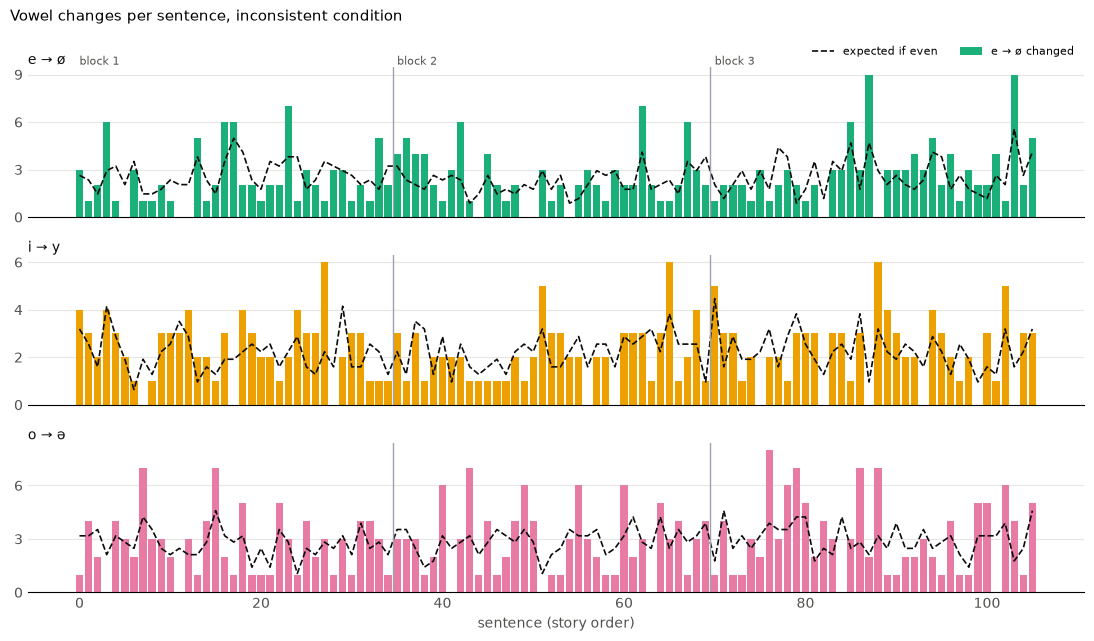

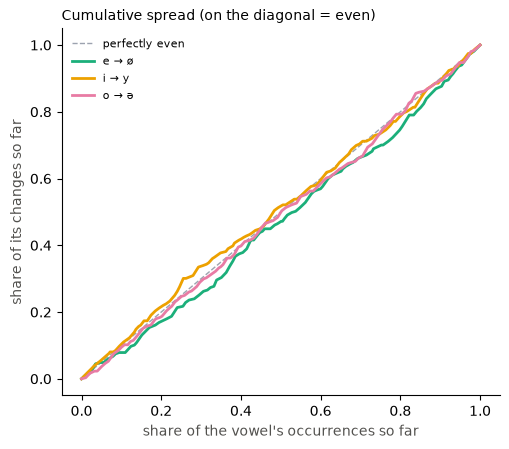

A curve above the diagonal = changes come earlier in the story than the vowel does; below = later.


In [15]:
# ── How are the inconsistent vowel substitutions spread over the story? ──────────────────────────
# Expected = the quota shared out in proportion to how many of that vowel each sentence / block has,
# i.e. what a perfectly even spread would give.
STORY = list(STORIES)[0]          # which story to look at
SPREAD_SEED = SEED                # same seed as the tables above

st = build_story(STORIES[STORY], SPREAD_SEED, name=STORY)
V = list(VOWEL_TARGETS)
NEW = {v: VOWEL_TARGETS[v]["new"] for v in V}

# per sentence: changed phonemes / words per vowel, and candidates (that vowel in the native sentence)
rows = []                                   # one per sentence, in story order
for b, sents in enumerate(st["inconsistent"]):
    for si, (nat_s, man_s) in enumerate(sents):
        r = dict(block=b + 1, sent=si, words=0, **{f"ch_{v}": 0 for v in V}, **{f"chw_{v}": 0 for v in V},
                 **{f"cand_{v}": 0 for v in V}, **{f"candw_{v}": 0 for v in V})
        for (a0, b0), (a1, b1) in zip(_word_spans(nat_s), _word_spans(man_s)):
            un, um = units(nat_s[a0:b0]), units(man_s[a1:b1])
            r["words"] += 1
            for v in V:
                n_cand = sum(u[0] == v for u in un)
                n_ch = sum(x[0] == v and y[0] == NEW[v] for x, y in zip(un, um)) if len(un) == len(um) else 0
                r[f"cand_{v}"] += n_cand; r[f"candw_{v}"] += n_cand > 0
                r[f"ch_{v}"] += n_ch;     r[f"chw_{v}"] += n_ch > 0
        rows.append(r)

tot_ch = {v: sum(r[f"ch_{v}"] for r in rows) for v in V}
tot_cand = {v: sum(r[f"cand_{v}"] for r in rows) for v in V}
for r in rows:
    for v in V:
        r[f"exp_{v}"] = tot_ch[v] * r[f"cand_{v}"] / tot_cand[v] if tot_cand[v] else 0

# ---- 1. per block: observed vs expected ----
print(f"{STORY}, inconsistent condition (seed {SPREAD_SEED})\n")
print(f"{'block':<7}" + "".join(f"{v + ' changed / expected (% of ' + v + ')':>34}" for v in V))
blocks = sorted({r["block"] for r in rows})
for b in blocks + ["all"]:
    rs = rows if b == "all" else [r for r in rows if r["block"] == b]
    cells = []
    for v in V:
        ch, ex, cand = (sum(r[f"{k}_{v}"] for r in rs) for k in ("ch", "exp", "cand"))
        cells.append(f"{ch:>8} / {ex:6.1f}   ({100 * ch / cand if cand else 0:4.1f} %)")
    print(f"{str(b):<7}" + "".join(f"{c:>34}" for c in cells))

# chi-square: are the changes spread over the blocks in proportion to the candidates?
try:
    from scipy.stats import chisquare
    print()
    for v in V:
        obs = [sum(r[f"ch_{v}"] for r in rows if r["block"] == b) for b in blocks]
        exp = [sum(r[f"exp_{v}"] for r in rows if r["block"] == b) for b in blocks]
        if sum(exp) > 0:
            c, p = chisquare(obs, exp)
            print(f"{v}: χ²({len(blocks) - 1}) = {c:.2f}, p = {p:.3f}   "
                  + ("spread over blocks as expected" if p >= 0.05 else "⚠ blocks differ more than chance would give"))
except ImportError:
    print("(install scipy for a chi-square test per vowel)")

# ---- 2. per sentence: changes (bars) vs expected (line) ----
x = np.arange(len(rows))
COLV = dict(zip(V, ["#1baf7a", "#eda100", "#e87ba4", "#6250d6"]))
bounds = [i for i in range(1, len(rows)) if rows[i]["block"] != rows[i - 1]["block"]]
fig, axes = plt.subplots(len(V), 1, figsize=(11, 1.9 * len(V) + 0.8), sharex=True, squeeze=False)
for ax, v in zip(axes[:, 0], V):
    ax.bar(x, [r[f"ch_{v}"] for r in rows], 0.8, color=COLV[v], label=f"{v} → {NEW[v]} changed")
    ax.plot(x, [r[f"exp_{v}"] for r in rows], color="#0b0b0b", lw=1.2, ls="--", label="expected if even")
    for bx in bounds:
        ax.axvline(bx - 0.5, color="#9ca3af", lw=1)
    ax.set_title(f"{v} → {NEW[v]}", loc="left", fontsize=10, color="#0b0b0b", pad=2)
    ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(colors="#52514e", length=0)
    ax.yaxis.grid(True, color="#e7e6e2", lw=0.8); ax.set_axisbelow(True)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
axes[0, 0].legend(frameon=False, fontsize=8, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))
for b, start in zip(blocks, [0] + bounds):
    axes[0, 0].text(start, axes[0, 0].get_ylim()[1], f"block {b}", fontsize=8, color="#52514e", va="bottom")
axes[-1, 0].set_xlabel("sentence (story order)", color="#52514e")
fig.suptitle("Vowel changes per sentence, inconsistent condition", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

# ---- 3. cumulative: share of changes vs share of candidates along the story ----
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color="#9ca3af", lw=1, ls="--", label="perfectly even")
for v in V:
    cc = np.cumsum([r[f"cand_{v}"] for r in rows]) / max(tot_cand[v], 1)
    ch = np.cumsum([r[f"ch_{v}"] for r in rows]) / max(tot_ch[v], 1)
    ax.plot(np.r_[0, cc], np.r_[0, ch], color=COLV[v], lw=2, label=f"{v} → {NEW[v]}")
ax.set_xlabel("share of the vowel's occurrences so far", color="#52514e")
ax.set_ylabel("share of its changes so far", color="#52514e")
ax.set_title("Cumulative spread (on the diagonal = even)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("A curve above the diagonal = changes come earlier in the story than the vowel does; below = later.")